# Exploratory Data Analysis (EDA) — NFL Play-by-Play Dataset

## Introduction
Exploratory Data Analysis (EDA) helps us understand a dataset's structure, data quality, distributions, relationships, and patterns before further analysis.

This project uses the **NFL Play by Play 2009–2016** dataset. Each row generally represents a play from an NFL game. The analysis below is written to work with the columns available in the CSV; some questions and plots are skipped automatically if a particular column is not present.

## EDA workflow
1. Load and inspect the data
2. Clean column names and check missing/duplicate values
3. Understand data types and summary statistics
4. Analyze individual variables
5. Explore relationships between variables
6. Detect outliers
7. Create useful date/time features where possible
8. Summarize findings and limitations

## 1. Import the necessary libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Import the dataset

In [3]:
# Keep the CSV in the same folder as this notebook, or update the path below.
file_path = "NFL Play by Play 2009-2016 (v3).csv"

df = pd.read_csv(r"C:\Users\ohelm\OneDrive\Desktop\class\dataset\NFL Play by Play 2009-2016 (v3).csv", low_memory=False)
print("Dataset loaded successfully.")
print("Dataset shape (rows, columns):", df.shape)

Dataset loaded successfully.
Dataset shape (rows, columns): (362447, 102)


## 3. Display the first and last five rows

In [4]:
display(df.head())

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,FirstDown,posteam,DefensiveTeam,desc,PlayAttempted,Yards.Gained,sp,Touchdown,ExPointResult,TwoPointConv,DefTwoPoint,Safety,Onsidekick,PuntResult,PlayType,Passer,Passer_ID,PassAttempt,PassOutcome,PassLength,AirYards,YardsAfterCatch,QBHit,PassLocation,InterceptionThrown,Interceptor,Rusher,Rusher_ID,RushAttempt,RunLocation,RunGap,Receiver,Receiver_ID,Reception,ReturnResult,...,Tackler1,Tackler2,FieldGoalResult,FieldGoalDistance,Fumble,RecFumbTeam,RecFumbPlayer,Sack,Challenge.Replay,ChalReplayResult,Accepted.Penalty,PenalizedTeam,PenaltyType,PenalizedPlayer,Penalty.Yards,PosTeamScore,DefTeamScore,ScoreDiff,AbsScoreDiff,HomeTeam,AwayTeam,Timeout_Indicator,Timeout_Team,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post,No_Score_Prob,Opp_Field_Goal_Prob,Opp_Safety_Prob,Opp_Touchdown_Prob,Field_Goal_Prob,Safety_Prob,Touchdown_Prob,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2009-09-10,2009091000,1,1,NaN,15:00,15,3600.0,0.0,TEN,30.0,30.0,0,0,0.0,NaN,PIT,TEN,R.Bironas kicks 67 yards from TEN 30 to PIT 3....,1,39,0,0,NaN,NaN,NaN,0,0,NaN,Kickoff,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,M.Griffin,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001506,0.179749,0.006639,0.281138,0.213700,0.003592,0.313676,0.0,0.0,0.323526,2.014474,NaN,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009
1,2009-09-10,2009091000,1,1,1.0,14:53,15,3593.0,7.0,PIT,42.0,58.0,10,5,0.0,0.0,PIT,TEN,(14:53) B.Roethlisberger pass short left to H....,1,5,0,0,NaN,NaN,NaN,0,0,NaN,Pass,B.Roethlisberger,00-0022924,1,Complete,Short,-3,8,0,left,0,NaN,NaN,None,0,NaN,NaN,H.Ward,00-0017162,1,NaN,...,C.Hope,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.000969,0.108505,0.001061,0.169117,0.293700,0.003638,0.423011,0.0,0.0,2.338000,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009
2,2009-09-10,2009091000,1,1,2.0,14:16,15,3556.0,37.0,PIT,47.0,53.0,5,2,0.0,0.0,PIT,TEN,(14:16) W.Parker right end to PIT 44 for -3 ya...,1,-3,0,0,NaN,NaN,NaN,0,0,NaN,Run,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,W.Parker,00-0022250,1,right,end,NaN,None,0,NaN,...,S.Tulloch,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001057,0.105106,0.000981,0.162747,0.304805,0.003826,0.421478,0.0,0.0,2.415907,-1.402760,NaN,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009
3,2009-09-10,2009091000,1,1,3.0,13:35,14,3515.0,41.0,PIT,44.0,56.0,8,2,0.0,0.0,PIT,TEN,(13:35) (Shotgun) B.Roethlisberger pass incomp...,1,0,0,0,NaN,NaN,NaN,0,0,NaN,Pass,B.Roethlisberger,00-0022924,1,Incomplete Pass,Deep,34,0,0,right,0,NaN,NaN,None,0,NaN,NaN,M.Wallace,00-0026901,0,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001434,0.149088,0.001944,0.234801,0.289336,0.004776,0.318621,0.0,0.0,1.013147,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009
4,2009-09-10,2009091000,1,1,4.0,13:27,14,3507.0,8.0,PIT,44.0,56.0,8,2,0.0,1.0,PIT,TEN,(13:27) (Punt formation) D.Sepulveda punts 54 ...,1,0,0,0,NaN,NaN,NaN,0,0,Clean,Punt,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001861,0.213480,0.003279,0.322262,0.244603,0.006404,0.208111,0.0,0.0,-0.699436,2.097796,NaN,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009


In [5]:
display(df.tail())

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,FirstDown,posteam,DefensiveTeam,desc,PlayAttempted,Yards.Gained,sp,Touchdown,ExPointResult,TwoPointConv,DefTwoPoint,Safety,Onsidekick,PuntResult,PlayType,Passer,Passer_ID,PassAttempt,PassOutcome,PassLength,AirYards,YardsAfterCatch,QBHit,PassLocation,InterceptionThrown,Interceptor,Rusher,Rusher_ID,RushAttempt,RunLocation,RunGap,Receiver,Receiver_ID,Reception,ReturnResult,...,Tackler1,Tackler2,FieldGoalResult,FieldGoalDistance,Fumble,RecFumbTeam,RecFumbPlayer,Sack,Challenge.Replay,ChalReplayResult,Accepted.Penalty,PenalizedTeam,PenaltyType,PenalizedPlayer,Penalty.Yards,PosTeamScore,DefTeamScore,ScoreDiff,AbsScoreDiff,HomeTeam,AwayTeam,Timeout_Indicator,Timeout_Team,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post,No_Score_Prob,Opp_Field_Goal_Prob,Opp_Safety_Prob,Opp_Touchdown_Prob,Field_Goal_Prob,Safety_Prob,Touchdown_Prob,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
362442,2017-01-01,2017010102,20,4,1.0,00:22,1,22.0,6.0,GB,35.0,35.0,10,35,0.0,0.0,DET,GB,(:22) (Shotgun) M.Stafford pass deep middle to...,1,35,1,1,NaN,NaN,NaN,0,0,NaN,Pass,M.Stafford,00-0026498,1,Complete,Deep,35,0,0,middle,0,NaN,NaN,None,0,NaN,NaN,A.Boldin,00-0022084,1,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,17.0,31.0,-14.0,14.0,DET,GB,0,None,0,0,0,0,0,0.432210,0.022742,0.000105,0.016372,0.283459,0.000626,0.244487,0.000000,0.0,2.379997,4.620003,4.620003,0.0,0.051901,0.948099,0.093435,0.906565,0.051901,0.041534,0.041534,0.0,2016
362443,2017-01-01,2017010102,20,4,NaN,00:13,1,13.0,9.0,GB,15.0,15.0,0,35,0.0,0.0,DET,GB,"M.Prater extra point is GOOD, Center-D.Muhlbac...",1,0,1,0,Made,NaN,NaN,0,0,NaN,Extra Point,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,23.0,31.0,-8.0,8.0,DET,GB,0,None,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.931115,0.0,0.931115,0.068885,NaN,NaN,0.093435,0.906565,0.034069,0.965931,0.093435,-0.059366,NaN,NaN,2016
362444,2017-01-01,2017010102,21,4,NaN,00:13,1,13.0,0.0,DET,35.0,35.0,0,0,0.0,NaN,GB,DET,S.Martin kicks onside 11 yards from DET 35 to ...,1,0,0,0,NaN,NaN,NaN,0,1,NaN,Kickoff,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,J.Bell,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,31.0,24.0,7.0,7.0,DET,GB,0,None,0,0,0,0,0,0.723273,0.039083,0.002014,0.028291,0.109291,0.000420,0.097628,0.000000,0.0,0.692792,-0.692792,NaN,NaN,0.034069,0.965931,0.035708,0.964292,0.965931,-0.001639,NaN,NaN,2016
362445,2017-01-01,2017010102,21,4,1.0,00:12,1,12.0,1.0,DET,46.0,46.0,10,-1,0.0,0.0,GB,DET,(:12) A.Rodgers kneels to DET 47 for -1 yards.,1,-1,0,0,NaN,NaN,NaN,0,0,NaN,QB Kneel,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,00-0023459,0,NaN,NaN,NaN,None,0,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,31.0,24.0,7.0,7.0,DET,GB,0,None,0,0,0,0,0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,NaN,NaN,0.035708,0.964292,0.000000,1.000000,0.964292,0.035708,NaN,NaN,2016
362446,2017-01-01,2017010102,21,4,NaN,00:00,0,0.0,12.0,DET,46.0,46.0,0,-1,0.0,0.0,GB,DET,END GAME,1,0,0,0,NaN,NaN,NaN,0,0,NaN,End of Game,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,NaN,NaN,7.0,NaN,DET,GB,0,None,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,NaN,NaN,0.000000,1.000000,0.000000,1.000000,0.934245,0.000000,NaN,NaN,2016


## 4. Data cleaning

### 4.1 Standardize column names

In [6]:
# Remove leading/trailing spaces from column names
df.columns = df.columns.astype(str).str.strip()

print("Column names:")
print(df.columns.tolist())

Column names:
['Date', 'GameID', 'Drive', 'qtr', 'down', 'time', 'TimeUnder', 'TimeSecs', 'PlayTimeDiff', 'SideofField', 'yrdln', 'yrdline100', 'ydstogo', 'ydsnet', 'GoalToGo', 'FirstDown', 'posteam', 'DefensiveTeam', 'desc', 'PlayAttempted', 'Yards.Gained', 'sp', 'Touchdown', 'ExPointResult', 'TwoPointConv', 'DefTwoPoint', 'Safety', 'Onsidekick', 'PuntResult', 'PlayType', 'Passer', 'Passer_ID', 'PassAttempt', 'PassOutcome', 'PassLength', 'AirYards', 'YardsAfterCatch', 'QBHit', 'PassLocation', 'InterceptionThrown', 'Interceptor', 'Rusher', 'Rusher_ID', 'RushAttempt', 'RunLocation', 'RunGap', 'Receiver', 'Receiver_ID', 'Reception', 'ReturnResult', 'Returner', 'BlockingPlayer', 'Tackler1', 'Tackler2', 'FieldGoalResult', 'FieldGoalDistance', 'Fumble', 'RecFumbTeam', 'RecFumbPlayer', 'Sack', 'Challenge.Replay', 'ChalReplayResult', 'Accepted.Penalty', 'PenalizedTeam', 'PenaltyType', 'PenalizedPlayer', 'Penalty.Yards', 'PosTeamScore', 'DefTeamScore', 'ScoreDiff', 'AbsScoreDiff', 'HomeTeam', 

### 4.2 Inspect missing values

In [7]:
missing_count = df.isna().sum().sort_values(ascending=False)
missing_count = missing_count[missing_count > 0]

print("Columns with missing values:")
display(missing_count.to_frame("Missing_Count"))

missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_percent[missing_percent > 0].round(2).to_frame("Missing_Percent"))

Columns with missing values:


,Missing_Count
DefTwoPoint,362433
BlockingPlayer,362341
TwoPointConv,361919
ChalReplayResult,359476
RecFumbTeam,358513
...,...
Opp_Touchdown_Prob,148
Opp_Field_Goal_Prob,148
Opp_Safety_Prob,148
ExpPts,148


,Missing_Percent
DefTwoPoint,100.00
BlockingPlayer,99.97
TwoPointConv,99.85
ChalReplayResult,99.18
RecFumbTeam,98.91
...,...
Opp_Touchdown_Prob,0.04
Opp_Field_Goal_Prob,0.04
Opp_Safety_Prob,0.04
ExpPts,0.04


### 4.3 Remove completely empty columns
Completely empty columns do not contain usable information, so they can be removed. The original data file is not overwritten.

In [8]:
empty_columns = df.columns[df.isna().all()].tolist()
print("Completely empty columns:", empty_columns)

df = df.dropna(axis=1, how="all")
print("Shape after removing completely empty columns:", df.shape)

Completely empty columns: []
Shape after removing completely empty columns: (362447, 102)


### 4.4 Check and remove exact duplicate rows

In [9]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates().copy()
print("Shape after removing duplicate rows:", df.shape)

Duplicate rows found: 0
Shape after removing duplicate rows: (362447, 102)


### 4.5 Convert date/time columns when present
The dataset may use `Date` and/or play-clock columns. Convert the game date safely; invalid dates become missing values and are counted.

In [10]:
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    print("Date column converted. Invalid/missing dates:", df["Date"].isna().sum())
else:
    print("No column named 'Date' was found; date conversion skipped.")

print("\nData types:")
display(df.dtypes.astype(str).value_counts().to_frame("Column_Count"))

Date column converted. Invalid/missing dates: 0

Data types:


,Column_Count
object,37
float64,33
int64,31
datetime64[ns],1


## 5. Data understanding

In [11]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 362447 entries, 0 to 362446
Columns: 102 entries, Date to Season
dtypes: datetime64[ns](1), float64(33), int64(31), object(37)
memory usage: 284.8+ MB


In [12]:
print("Summary statistics for numeric columns:")
display(df.describe().T)

Summary statistics for numeric columns:


,count,mean,std,min,25%,50%,75%,max
GameID,362447.0,2.012664e+09,2.292258e+06,2.009091e+09,2.011091e+09,2.013091e+09,2.015091e+09,2.017010e+09
Drive,362447.0,1.234709e+01,7.168173e+00,1.000000e+00,6.000000e+00,1.200000e+01,1.800000e+01,3.500000e+01
qtr,362447.0,2.578231e+00,1.130259e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
down,308229.0,2.001226e+00,1.006003e+00,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00
TimeUnder,362447.0,7.386076e+00,4.642132e+00,0.000000e+00,3.000000e+00,7.000000e+00,1.100000e+01,1.500000e+01
...,...,...,...,...,...,...,...,...
Win_Prob,340454.0,5.013111e-01,2.882074e-01,0.000000e+00,2.749637e-01,5.043494e-01,7.269954e-01,1.000000e+00
WPA,357630.0,2.163278e-03,4.532620e-02,-9.972143e-01,-1.458923e-02,0.000000e+00,1.480035e-02,9.948482e-01
airWPA,141709.0,1.520890e-02,5.642153e-02,-9.998808e-01,-1.135466e-02,3.556632e-03,3.570156e-02,9.948482e-01
yacWPA,141491.0,-1.049184e-02,6.797185e-02,-9.866730e-01,-1.862274e-02,0.000000e+00,1.137056e-02,1.000000e+00


In [13]:
print("Summary statistics for all columns:")
display(df.describe(include="all").T)

Summary statistics for all columns:


,count,unique,top,freq,first,last,mean,std,min,25%,50%,75%,max
Date,362447,376,2016-01-03 00:00:00,2872,2009-09-10,2017-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GameID,362447.0,NaN,NaN,NaN,NaT,NaT,2012664429.993891,2292258.152951,2009091000.0,2011091106.0,2013090806.0,2015091306.0,2017010115.0
Drive,362447.0,NaN,NaN,NaN,NaT,NaT,12.347088,7.168173,1.0,6.0,12.0,18.0,35.0
qtr,362447.0,NaN,NaN,NaN,NaT,NaT,2.578231,1.130259,1.0,2.0,3.0,4.0,5.0
down,308229.0,NaN,NaN,NaN,NaT,NaT,2.001226,1.006003,1.0,1.0,2.0,3.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Win_Prob,340454.0,NaN,NaN,NaN,NaT,NaT,0.501311,0.288207,0.0,0.274964,0.504349,0.726995,1.0
WPA,357630.0,NaN,NaN,NaN,NaT,NaT,0.002163,0.045326,-0.997214,-0.014589,0.0,0.0148,0.994848
airWPA,141709.0,NaN,NaN,NaN,NaT,NaT,0.015209,0.056422,-0.999881,-0.011355,0.003557,0.035702,0.994848
yacWPA,141491.0,NaN,NaN,NaN,NaT,NaT,-0.010492,0.067972,-0.986673,-0.018623,0.0,0.011371,1.0


In [14]:
print("Number of unique values per column:")
display(df.nunique(dropna=True).sort_values(ascending=False).to_frame("Unique_Values"))

Number of unique values per column:


,Unique_Values
desc,335003
WPA,326415
Away_WP_post,323708
Home_WP_post,323604
Away_WP_pre,323041
...,...
Challenge.Replay,2
ChalReplayResult,2
Accepted.Penalty,2
Timeout_Indicator,2


## 6. Univariate analysis

Univariate analysis examines one column at a time. The following cells automatically select suitable columns from the dataset.

### 6.1 Categorical column frequency counts

In [15]:
# Common NFL categorical columns, followed by other low-cardinality text columns
preferred_categorical = [
    "posteam", "DefTeam", "HomeTeam", "AwayTeam", "play_type",
    "PlayType", "desc", "quarter", "qtr", "down", "Season"
]
available_preferred = [c for c in preferred_categorical if c in df.columns]

# Add other categorical columns with a manageable number of unique values
other_categorical = [
    c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in available_preferred and 1 < df[c].nunique(dropna=True) <= 30
]
categorical_cols = (available_preferred + other_categorical)[:8]

if categorical_cols:
    for col in categorical_cols:
        print(f"\nValue counts for {col}:")
        display(df[col].value_counts(dropna=False).head(15).to_frame("Count"))
else:
    print("No suitable categorical columns found.")


Value counts for posteam:


,Count
NaN,21979
NE,11131
NO,11120
DEN,11019
PHI,11014
DET,10982
HOU,10944
BAL,10885
IND,10854
GB,10771



Value counts for HomeTeam:


,Count
NE,11714
PHI,11704
DEN,11661
OAK,11545
NO,11543
BUF,11542
IND,11469
CLE,11449
ARI,11444
NYG,11442



Value counts for AwayTeam:


...

,Count
4,100198
2,99701
3,80649
1,79291
5,2608



Value counts for down:


,Count
1.0,123682
2.0,92586
3.0,59862
NaN,54218
4.0,32099



Value counts for Season:


,Count
2015,46129
2016,45736
2014,45502
2012,45415
2013,45248
2011,45070
2010,44751
2009,44596


### 6.2 Plot the most common values of selected categorical columns

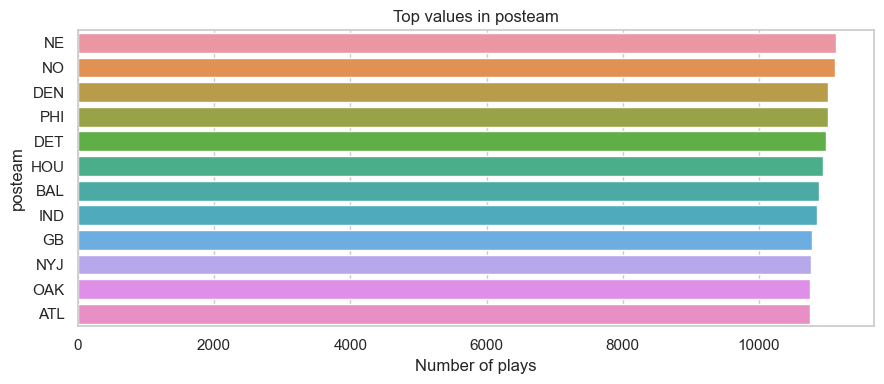

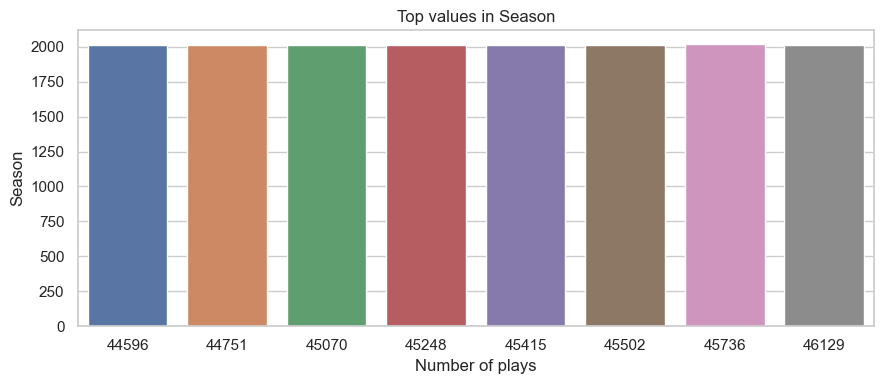

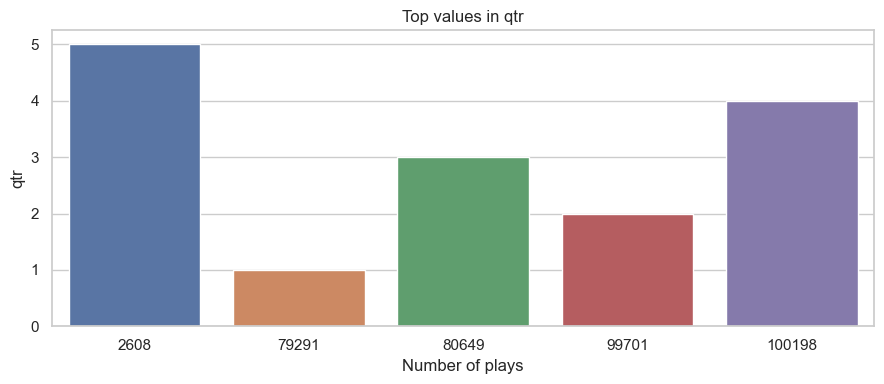

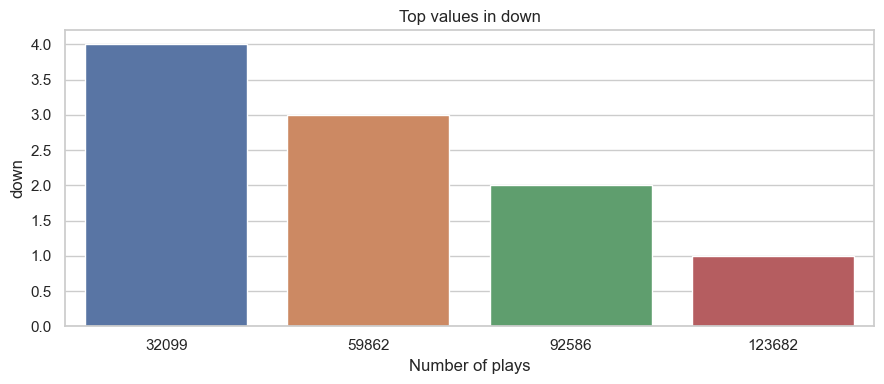

In [16]:
plot_cols = [c for c in ["play_type", "posteam", "DefTeam", "Season", "qtr", "down"] if c in df.columns]

for col in plot_cols[:4]:
    counts = df[col].value_counts().head(12)
    if not counts.empty:
        plt.figure(figsize=(9, 4))
        sns.barplot(x=counts.values, y=counts.index)
        plt.title(f"Top values in {col}")
        plt.xlabel("Number of plays")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

### 6.3 Numerical distributions

Number of numeric columns: 64
['GameID', 'Drive', 'qtr', 'down', 'TimeUnder', 'TimeSecs', 'PlayTimeDiff', 'yrdln', 'yrdline100', 'ydstogo', 'ydsnet', 'GoalToGo', 'FirstDown', 'PlayAttempted', 'Yards.Gained', 'sp', 'Touchdown', 'Safety', 'Onsidekick', 'PassAttempt', 'AirYards', 'YardsAfterCatch', 'QBHit', 'InterceptionThrown', 'RushAttempt', 'Reception', 'FieldGoalDistance', 'Fumble', 'Sack', 'Challenge.Replay', 'Accepted.Penalty', 'Penalty.Yards', 'PosTeamScore', 'DefTeamScore', 'ScoreDiff', 'AbsScoreDiff', 'Timeout_Indicator', 'posteam_timeouts_pre', 'HomeTimeouts_Remaining_Pre', 'AwayTimeouts_Remaining_Pre', 'HomeTimeouts_Remaining_Post', 'AwayTimeouts_Remaining_Post', 'No_Score_Prob', 'Opp_Field_Goal_Prob', 'Opp_Safety_Prob', 'Opp_Touchdown_Prob', 'Field_Goal_Prob', 'Safety_Prob', 'Touchdown_Prob', 'ExPoint_Prob', 'TwoPoint_Prob', 'ExpPts', 'EPA', 'airEPA', 'yacEPA', 'Home_WP_pre', 'Away_WP_pre', 'Home_WP_post', 'Away_WP_post', 'Win_Prob', 'WPA', 'airWPA', 'yacWPA', 'Season']


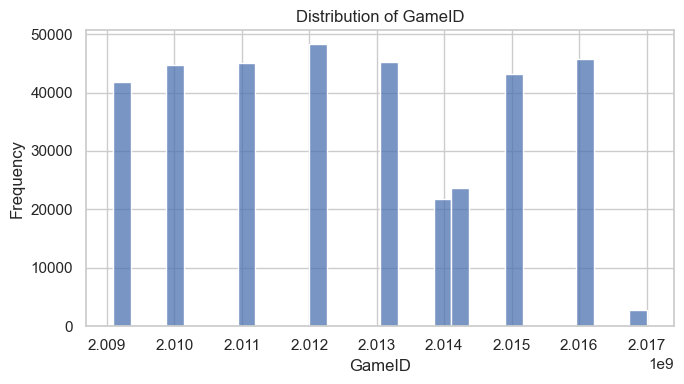

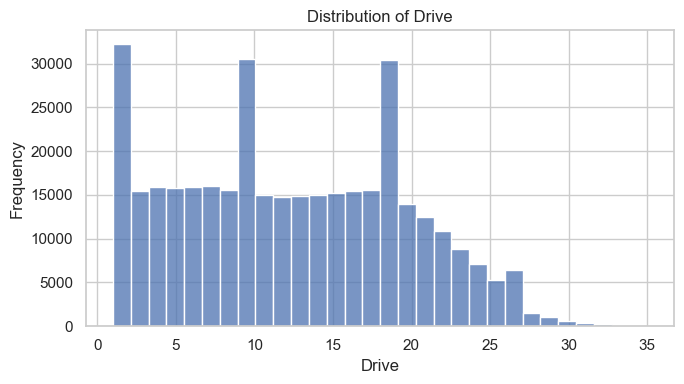

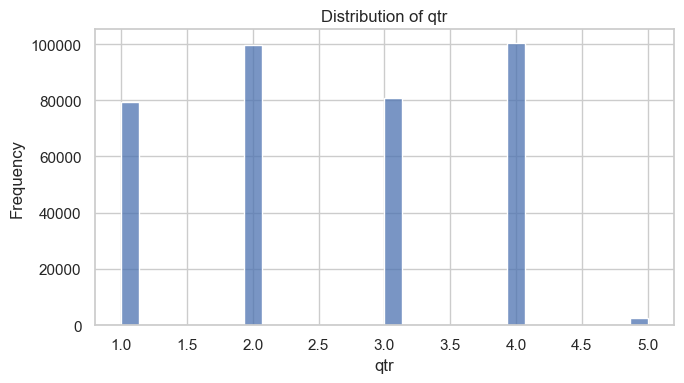

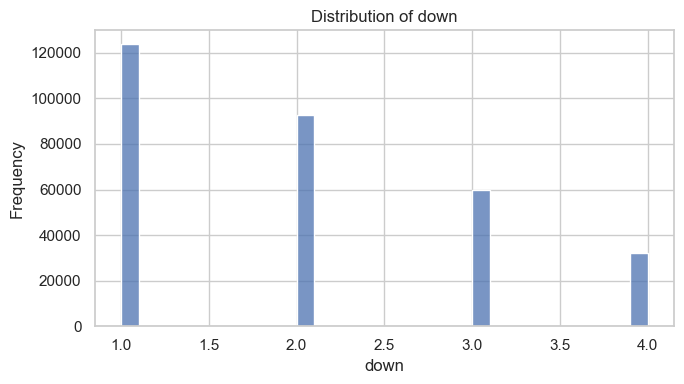

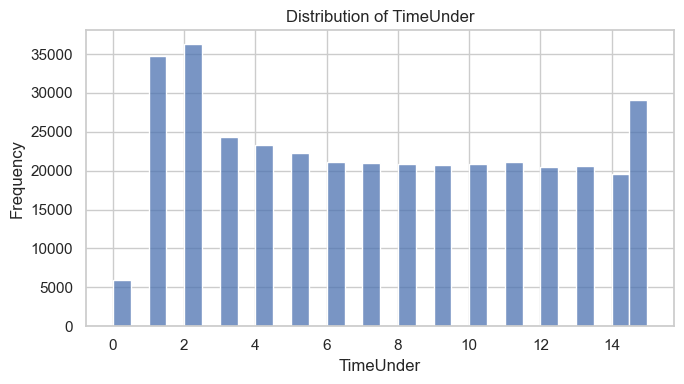

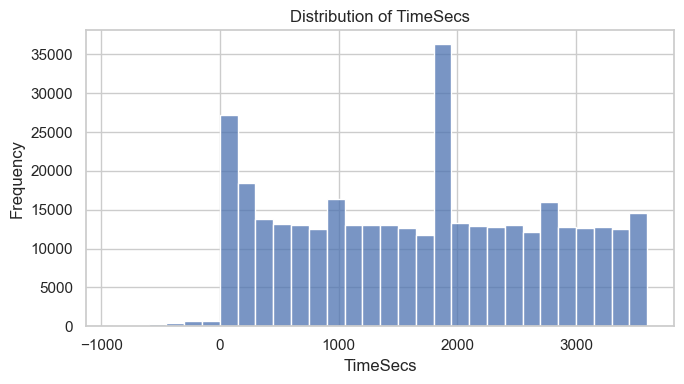

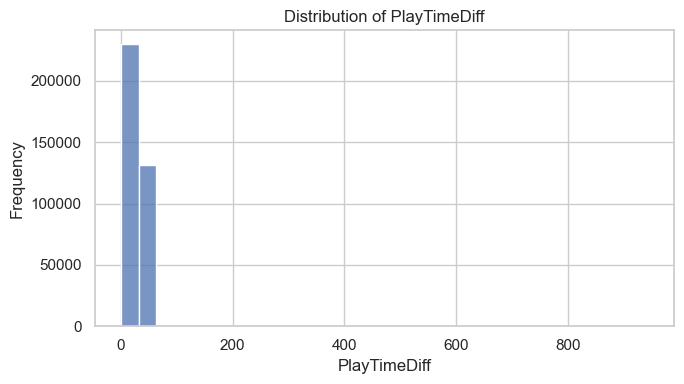

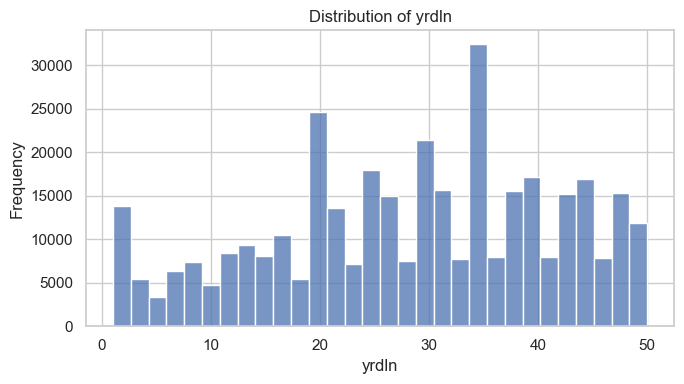

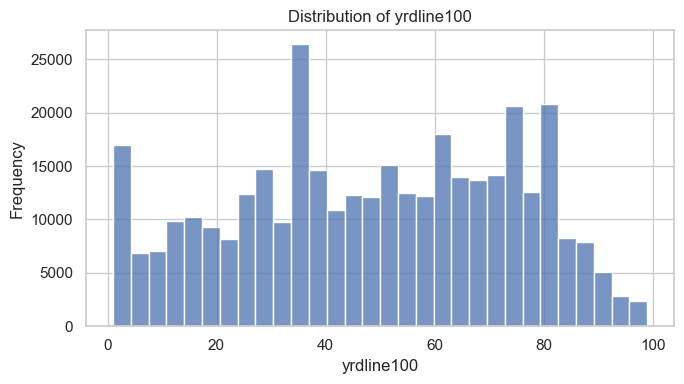

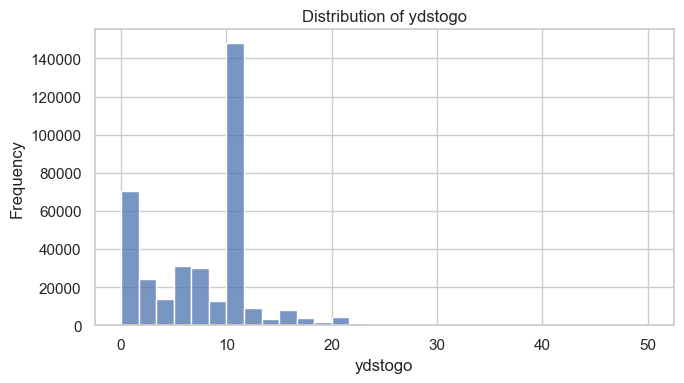

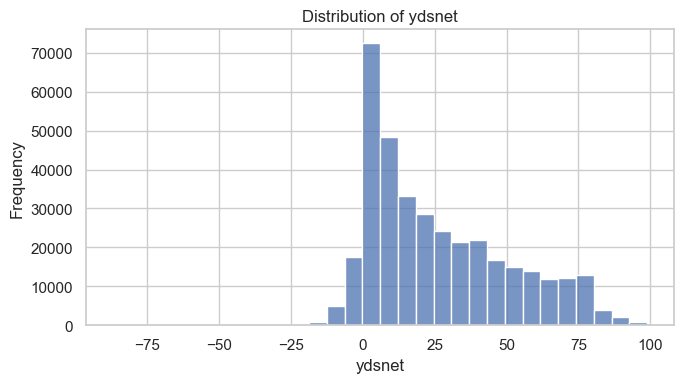

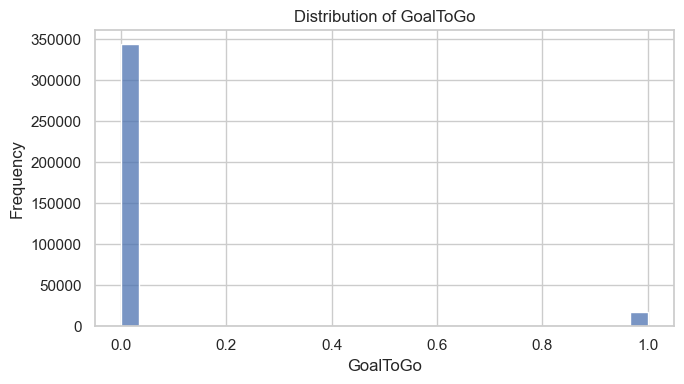

In [17]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Number of numeric columns:", len(numeric_cols))
print(numeric_cols)

# Plot a manageable sample of numeric columns to avoid producing too many figures
for col in numeric_cols[:12]:
    values = df[col].dropna()
    if not values.empty:
        plt.figure(figsize=(7, 4))
        sns.histplot(values, bins=30, kde=False)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

## 7. NFL-focused questions and analysis

These questions are adapted to common NFL play-by-play fields. A cell checks whether its required columns exist before running, so the notebook will not fail simply because a particular version of the dataset uses different column names.

In [18]:
# 1. How many plays are recorded for each team on offense?
team_col = next((c for c in ["posteam", "OffenseTeam", "offense_team"] if c in df.columns), None)
if team_col:
    display(df[team_col].value_counts().to_frame("Play_Count"))
else:
    print("Offensive team column not found.")

,Play_Count
NE,11131
NO,11120
DEN,11019
PHI,11014
DET,10982
HOU,10944
BAL,10885
IND,10854
GB,10771
NYJ,10769


In [19]:
# 2. What are the most common play types?
play_type_col = next((c for c in ["play_type", "PlayType", "playType"] if c in df.columns), None)
if play_type_col:
    display(df[play_type_col].value_counts(dropna=False).to_frame("Count"))
else:
    print("Play-type column not found.")

,Count
Pass,141866
Run,107448
Kickoff,20846
Punt,19557
No Play,18996
Timeout,14393
Sack,9448
Extra Point,9008
Field Goal,7902
Quarter End,4217


In [20]:
# 3. What is the average yardage gained by play type?
yards_col = next((c for c in ["yards_gained", "Yards.Gained", "YardsGained"] if c in df.columns), None)
if play_type_col and yards_col:
    display(df.groupby(play_type_col, dropna=False)[yards_col].agg(["count", "mean", "median"]).sort_values("mean", ascending=False))
else:
    print("Play-type and/or yards-gained column not found.")

,count,mean,median
PlayType,,,
Kickoff,20846,12.645927,11.0
Pass,141866,7.187381,4.0
Punt,19557,4.691108,0.0
Run,107448,4.378062,3.0
No Play,18996,2.206149,0.0
Field Goal,7902,0.264237,0.0
Timeout,14393,0.008129,0.0
End of Game,1759,0.002843,0.0
Extra Point,9008,0.000000,0.0


In [21]:
# 4. How does yardage gained vary by down?
down_col = next((c for c in ["down", "Down"] if c in df.columns), None)
if down_col and yards_col:
    display(df.groupby(down_col, dropna=False)[yards_col].describe())
else:
    print("Down and/or yards-gained column not found.")

,count,mean,std,min,25%,50%,75%,max
down,,,,,,,,
1.0,123682.0,5.284690,8.670737,-22.0,0.0,3.0,8.0,99.0
2.0,92586.0,5.200365,8.363035,-74.0,0.0,3.0,8.0,95.0
3.0,59862.0,5.236277,9.575391,-34.0,0.0,2.0,9.0,99.0
4.0,32099.0,3.504502,9.013494,-28.0,0.0,0.0,3.0,99.0
NaN,54218.0,4.864196,10.821918,-12.0,0.0,0.0,0.0,99.0


In [22]:
# 5. Which teams have the highest average yards gained per play?
if team_col and yards_col:
    team_yards = df.groupby(team_col)[yards_col].agg(["count", "mean"]).sort_values("mean", ascending=False)
    display(team_yards)
else:
    print("Team and/or yards-gained column not found.")

,count,mean
posteam,,
NO,11120,5.730755
NYG,10666,5.624977
PIT,10499,5.619869
DAL,10489,5.603299
WAS,10619,5.595065
CHI,10327,5.495788
NE,11131,5.467164
SD,10661,5.450802
GB,10771,5.450190


In [23]:
# 6. How often are plays marked as touchdowns or scoring plays?
# Inspect candidate scoring columns; meaning can vary by dataset version.
scoring_candidates = [c for c in ["Touchdown", "touchdown", "TDP", "FirstDown", "first_down", "Score", "score"] if c in df.columns]
print("Potential scoring/first-down columns found:", scoring_candidates)
for col in scoring_candidates:
    print(f"\n{col}:")
    display(df[col].value_counts(dropna=False).head(10).to_frame("Count"))

Potential scoring/first-down columns found: ['Touchdown', 'FirstDown']

Touchdown:


,Count
0,351876
1,10571



FirstDown:


,Count
0.0,238765
1.0,98085
NaN,25597


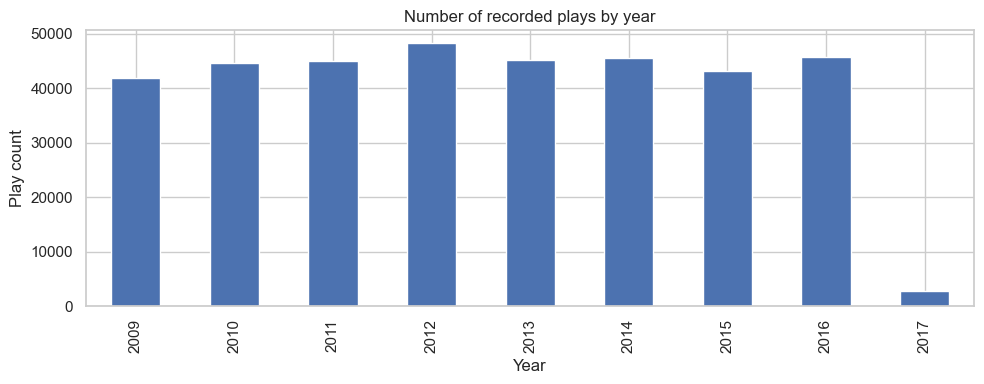

In [24]:
# 7. If game date and team columns are available, inspect play counts over time.
if "Date" in df.columns and team_col:
    date_summary = df.dropna(subset=["Date"]).groupby(df["Date"].dt.to_period("Y")).size()
    if not date_summary.empty:
        plt.figure(figsize=(10, 4))
        date_summary.plot(kind="bar")
        plt.title("Number of recorded plays by year")
        plt.xlabel("Year")
        plt.ylabel("Play count")
        plt.tight_layout()
        plt.show()
else:
    print("Date and/or team column not found; time trend skipped.")

## 8. Bivariate and multivariate analysis

## Statistical graphs and summary analysis

These graphs use the actual values in the loaded NFL dataset. They are intended to add a statistical perspective to the EDA: distributions, central tendency, spread, categorical frequencies, and relationships between numerical variables.

In [25]:
# Setup for statistical graphs (safe to rerun before this section)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Recreate helper column names so graph cells also work if run separately.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
yards_col = next((c for c in ["yards_gained", "Yards.Gained", "YardsGained"] if c in df.columns), None)
play_type_col = next((c for c in ["play_type", "PlayType", "playType"] if c in df.columns), None)
down_col = next((c for c in ["down", "Down"] if c in df.columns), None)
print("Statistical graph setup complete.")

Statistical graph setup complete.


### 1. Descriptive statistics: mean, median, and standard deviation

In [26]:
# Compare mean and median for selected numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
stats_cols = [c for c in numeric_cols if df[c].notna().sum() > 0][:8]

if stats_cols:
    stats_table = df[stats_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
    display(stats_table.sort_values("std", ascending=False))
else:
    print("No numeric columns are available for descriptive statistics.")

,count,mean,median,std,min,max
GameID,362447.0,2.012664e+09,2.013091e+09,2.292258e+06,2.009091e+09,2.017010e+09
TimeSecs,362259.0,1.695234e+03,1.800000e+03,1.063066e+03,-9.000000e+02,3.600000e+03
PlayTimeDiff,362073.0,2.057465e+01,1.700000e+01,1.803049e+01,0.000000e+00,9.430000e+02
yrdln,361724.0,2.841354e+01,3.000000e+01,1.300235e+01,1.000000e+00,5.000000e+01
Drive,362447.0,1.234709e+01,1.200000e+01,7.168173e+00,1.000000e+00,3.500000e+01
TimeUnder,362447.0,7.386076e+00,7.000000e+00,4.642132e+00,0.000000e+00,1.500000e+01
qtr,362447.0,2.578231e+00,3.000000e+00,1.130259e+00,1.000000e+00,5.000000e+00
down,308229.0,2.001226e+00,2.000000e+00,1.006003e+00,1.000000e+00,4.000000e+00


### 2. Mean versus median chart

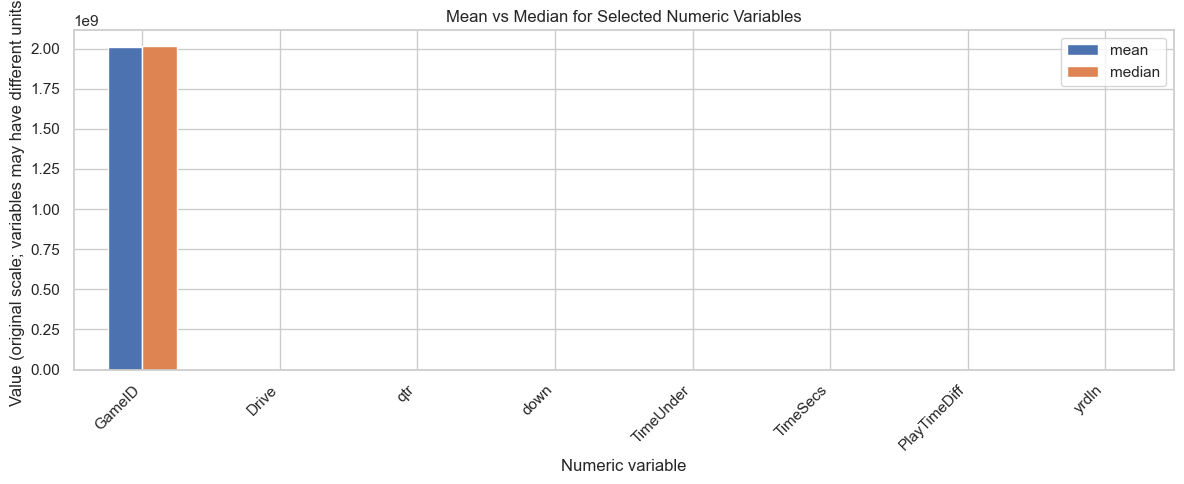

In [27]:
if stats_cols:
    comparison = df[stats_cols].agg(["mean", "median"]).T
    # Standardize each column for a fair visual comparison when scales differ.
    comparison_z = (comparison - comparison.mean()) / comparison.std(ddof=0).replace(0, np.nan)
    comparison.plot(kind="bar", figsize=(12, 5))
    plt.title("Mean vs Median for Selected Numeric Variables")
    plt.ylabel("Value (original scale; variables may have different units)")
    plt.xlabel("Numeric variable")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available to compare mean and median.")

### 3. Distribution and skewness of yardage (when available)

Yards gained — statistical summary


,Yards_Gained
count,362447.000000
mean,5.034595
std,9.144627
min,-74.000000
25%,0.000000
50%,1.000000
75%,7.000000
max,99.000000


Skewness: 2.935
Kurtosis: 14.164


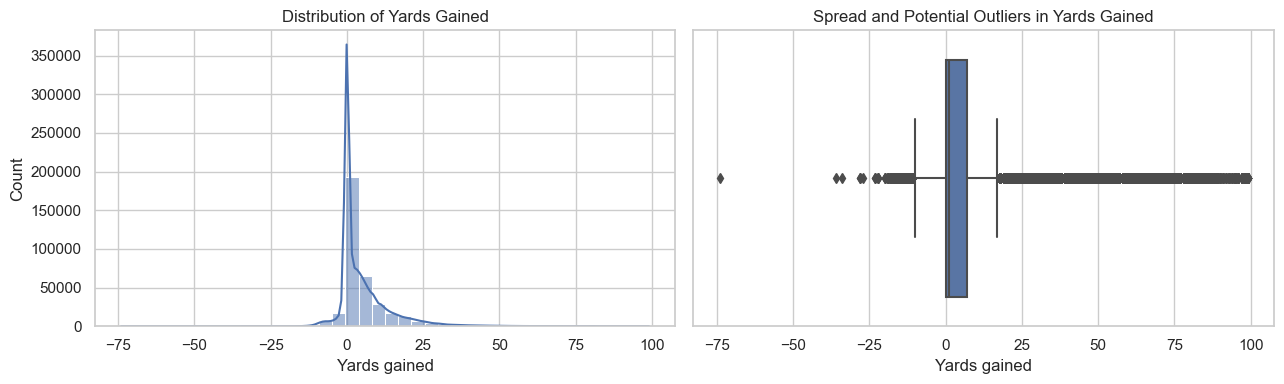

In [28]:
yards_col = next((c for c in ["yards_gained", "Yards.Gained", "YardsGained"] if c in df.columns), None)

if yards_col:
    yards = pd.to_numeric(df[yards_col], errors="coerce").dropna()
    if not yards.empty:
        print("Yards gained — statistical summary")
        display(yards.describe().to_frame("Yards_Gained"))
        print("Skewness:", round(yards.skew(), 3))
        print("Kurtosis:", round(yards.kurtosis(), 3))

        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        sns.histplot(yards, bins=40, kde=True, ax=axes[0])
        axes[0].set_title("Distribution of Yards Gained")
        axes[0].set_xlabel("Yards gained")
        sns.boxplot(x=yards, ax=axes[1])
        axes[1].set_title("Spread and Potential Outliers in Yards Gained")
        axes[1].set_xlabel("Yards gained")
        plt.tight_layout()
        plt.show()
else:
    print("No recognized yards-gained column found; yardage graphs skipped.")

### 4. Correlation matrix for selected numeric variables

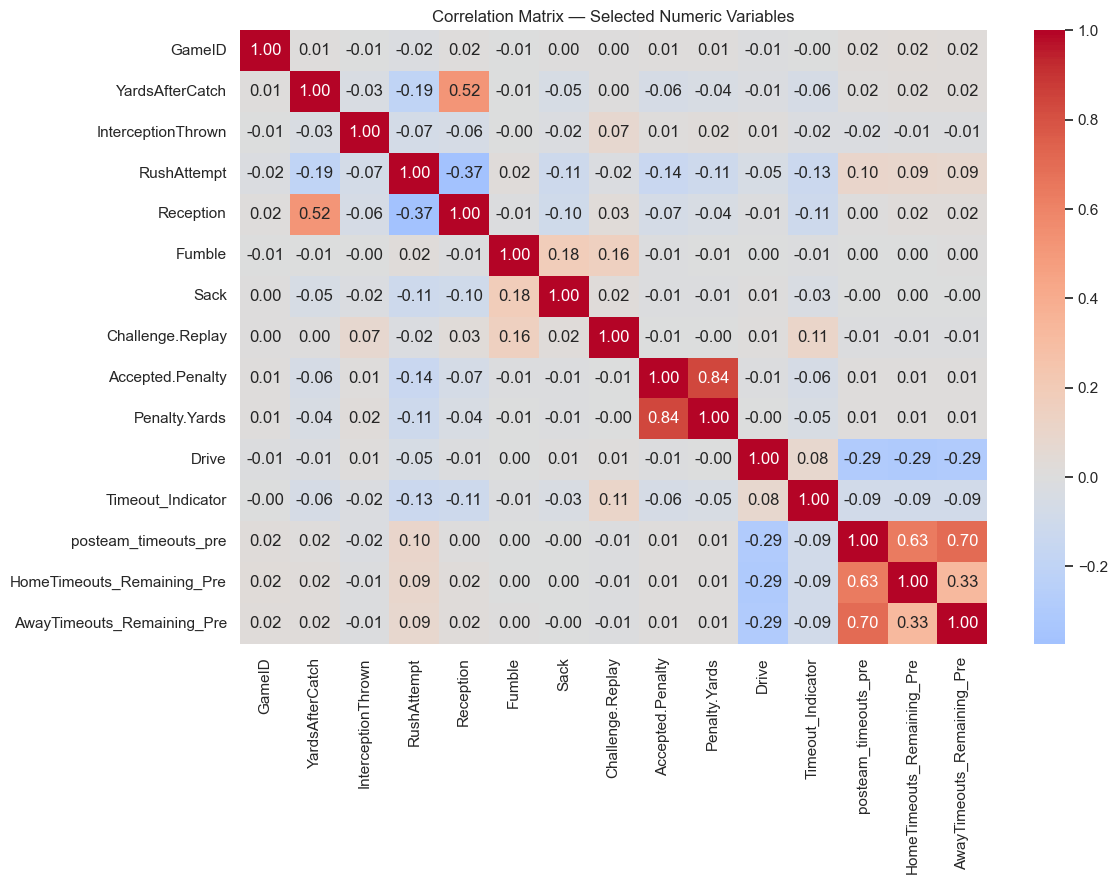

Correlation
Accepted.Penalty           Penalty.Yards                  0.838259
posteam_timeouts_pre       AwayTimeouts_Remaining_Pre     0.703413
                           HomeTimeouts_Remaining_Pre     0.631154
YardsAfterCatch            Reception                      0.518477
RushAttempt                Reception                     -0.373341
HomeTimeouts_Remaining_Pre AwayTimeouts_Remaining_Pre     0.327831
Drive                      HomeTimeouts_Remaining_Pre    -0.293891
                           AwayTimeouts_Remaining_Pre    -0.291790
                           posteam_timeouts_pre          -0.288516
YardsAfterCatch            RushAttempt                   -0.193246

In [29]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    # Use up to 15 numeric columns with the most non-missing observations.
    corr_cols = numeric_df.notna().sum().sort_values(ascending=False).head(15).index
    corr = numeric_df[corr_cols].corr()
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False)
    plt.title("Correlation Matrix — Selected Numeric Variables")
    plt.tight_layout()
    plt.show()

    # List the strongest non-duplicate correlations, excluding self-correlations.
    corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
    if not corr_pairs.empty:
        display(corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index)
                .head(10).to_frame("Correlation"))
else:
    print("At least two numeric columns are required for correlation analysis.")

### 5. Categorical proportions: most common play types

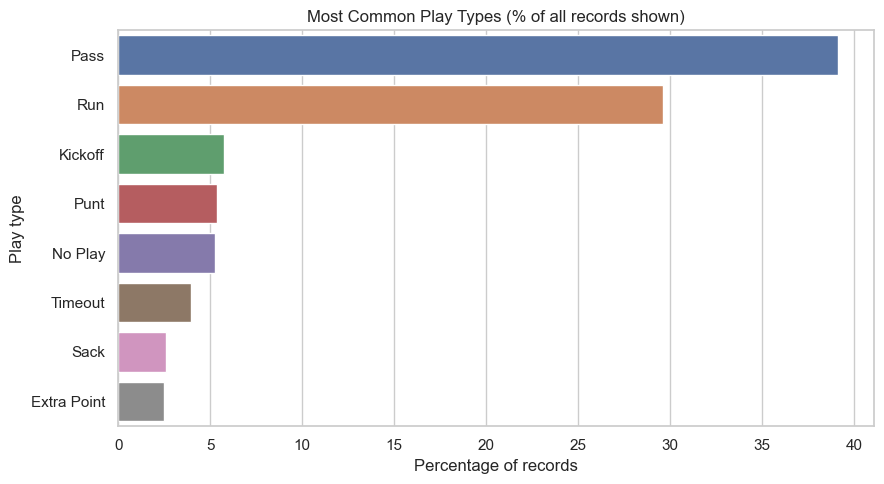

,Percent
Pass,39.14
Run,29.65
Kickoff,5.75
Punt,5.40
No Play,5.24
Timeout,3.97
Sack,2.61
Extra Point,2.49


In [30]:
play_type_col = next((c for c in ["play_type", "PlayType", "playType"] if c in df.columns), None)
if play_type_col:
    proportions = df[play_type_col].fillna("Missing").value_counts(normalize=True).head(8) * 100
    plt.figure(figsize=(9, 5))
    sns.barplot(x=proportions.values, y=proportions.index)
    plt.title("Most Common Play Types (% of all records shown)")
    plt.xlabel("Percentage of records")
    plt.ylabel("Play type")
    plt.tight_layout()
    plt.show()
    display(proportions.round(2).to_frame("Percent"))
else:
    print("No recognized play-type column found; categorical proportion graph skipped.")

### 6. Yardage by down: compare medians and spread

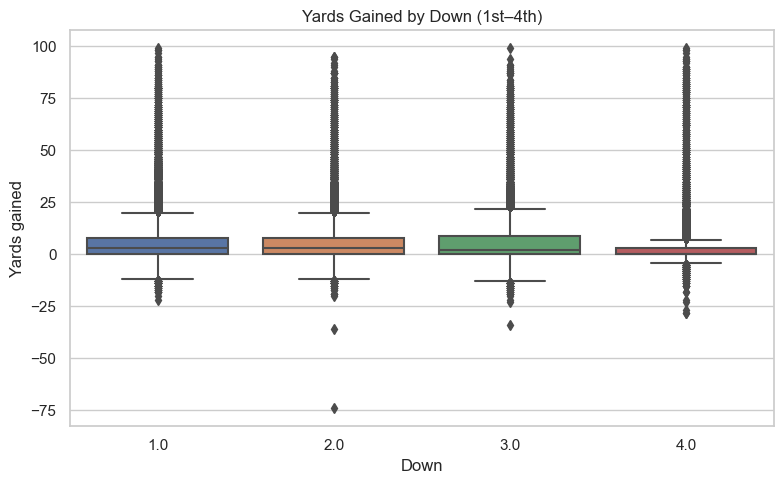

,count,mean,median,std
down,,,,
1.0,123682,5.284690,3.0,8.670737
2.0,92586,5.200365,3.0,8.363035
3.0,59862,5.236277,2.0,9.575391
4.0,32099,3.504502,0.0,9.013494


In [31]:
down_col = next((c for c in ["down", "Down"] if c in df.columns), None)
if down_col and yards_col:
    plot_data = df[[down_col, yards_col]].copy()
    plot_data[down_col] = pd.to_numeric(plot_data[down_col], errors="coerce")
    plot_data[yards_col] = pd.to_numeric(plot_data[yards_col], errors="coerce")
    plot_data = plot_data.dropna()
    plot_data = plot_data[plot_data[down_col].between(1, 4)]
    if not plot_data.empty:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=plot_data, x=down_col, y=yards_col)
        plt.title("Yards Gained by Down (1st–4th)")
        plt.xlabel("Down")
        plt.ylabel("Yards gained")
        plt.tight_layout()
        plt.show()
        display(plot_data.groupby(down_col)[yards_col].agg(["count", "mean", "median", "std"]))
    else:
        print("No valid 1st–4th down yardage rows available.")
else:
    print("Down and/or yards-gained columns are unavailable; comparison skipped.")

### 7. Scatter plot: relationship between two numeric variables

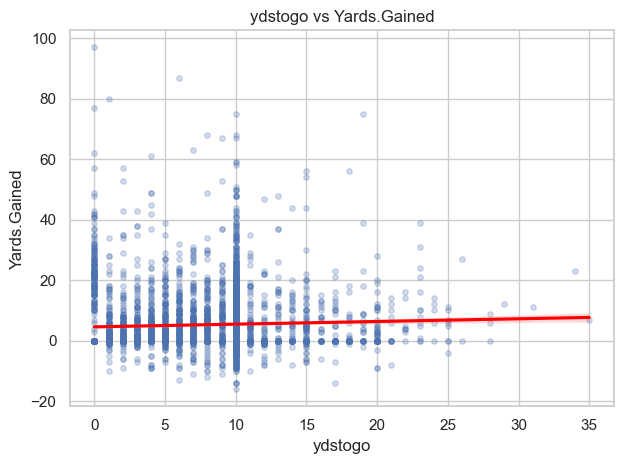

Pearson correlation: 0.047


In [32]:
# Prefer yards gained and a common game-state variable if present.
candidate_x = next((c for c in ["ydstogo", "YardsToGo", "yards_to_go", "down"] if c in df.columns and c != yards_col), None)
if candidate_x and yards_col:
    scatter_df = df[[candidate_x, yards_col]].copy()
    scatter_df[candidate_x] = pd.to_numeric(scatter_df[candidate_x], errors="coerce")
    scatter_df[yards_col] = pd.to_numeric(scatter_df[yards_col], errors="coerce")
    scatter_df = scatter_df.dropna()
    if len(scatter_df) > 5000:
        scatter_df = scatter_df.sample(5000, random_state=42)
    if not scatter_df.empty:
        sns.regplot(data=scatter_df, x=candidate_x, y=yards_col,
                    scatter_kws={"alpha": 0.25, "s": 15}, line_kws={"color": "red"})
        plt.title(f"{candidate_x} vs {yards_col}")
        plt.tight_layout()
        plt.show()
        print("Pearson correlation:", round(scatter_df[candidate_x].corr(scatter_df[yards_col]), 3))
else:
    print("Suitable numeric columns for a scatter plot were not found.")

### Statistical interpretation guide

When you run the notebook, use the displayed outputs to explain:
- **Mean vs median:** large differences can indicate skewed distributions or extreme plays.
- **Standard deviation and IQR/boxplots:** describe how variable play outcomes are and whether unusual values exist.
- **Correlation:** values near +1 indicate a strong positive linear relationship; values near -1 indicate a strong negative linear relationship; values near 0 indicate little linear relationship. Correlation does not prove causation.
- **Categorical percentages:** show which play types make up the largest share of records.
- **Group comparisons:** compare counts, means, medians, and spread by down or play type.

The exact findings depend on the CSV you run this notebook against; do not write conclusions before reviewing the generated outputs.

### 8.1 Correlation between numeric variables

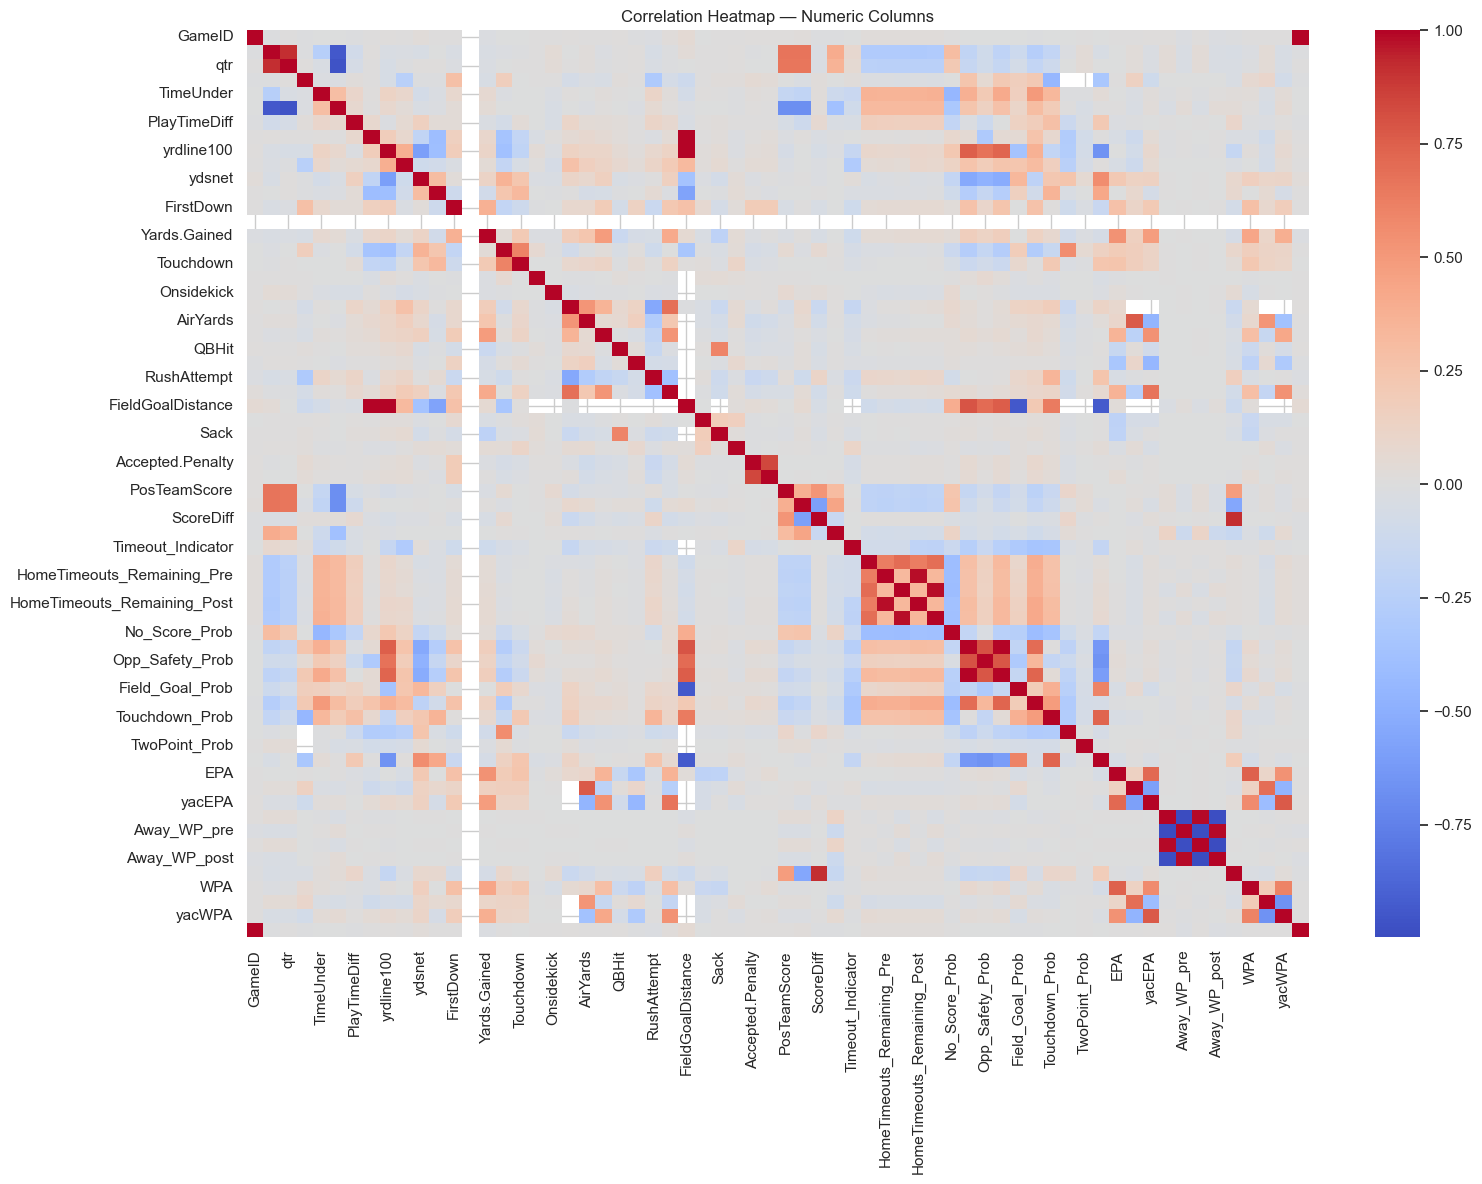

In [33]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr()
    plt.figure(figsize=(min(16, 1 + len(corr.columns) * 0.6), min(12, 1 + len(corr.columns) * 0.5)))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap — Numeric Columns")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric columns are needed for a correlation heatmap.")

### 8.2 Compare numeric outcomes across categories

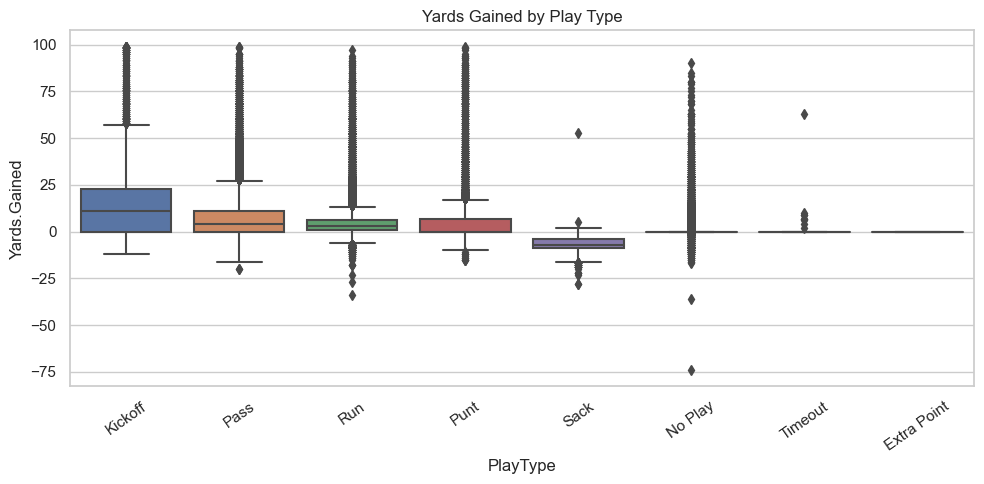

In [34]:
# Compare yards gained across play type and down, when available
if yards_col and play_type_col:
    plt.figure(figsize=(10, 5))
    order = df[play_type_col].value_counts().head(8).index
    sns.boxplot(data=df[df[play_type_col].isin(order)], x=play_type_col, y=yards_col)
    plt.title("Yards Gained by Play Type")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns for this comparison were not found.")

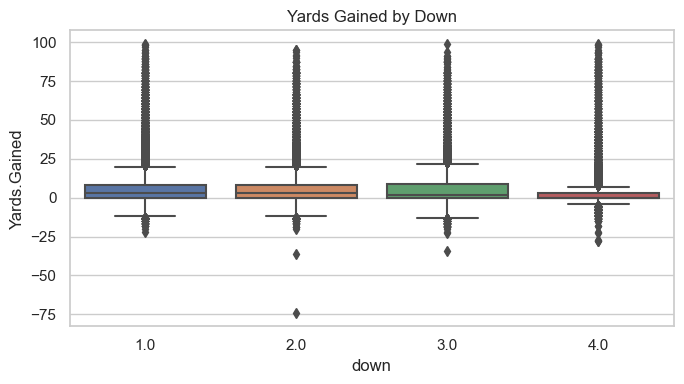

In [35]:
# Relationship between yards gained and numeric down, if both are available
if yards_col and down_col:
    temp = df[[down_col, yards_col]].apply(pd.to_numeric, errors="coerce").dropna()
    if not temp.empty:
        plt.figure(figsize=(7, 4))
        sns.boxplot(data=temp, x=down_col, y=yards_col)
        plt.title("Yards Gained by Down")
        plt.tight_layout()
        plt.show()
else:
    print("Required columns for yards gained by down were not found.")

## 9. Outlier detection

Boxplots can help identify unusually high or low values. In play-by-play data, extreme yardage or scoring-related values may be legitimate plays, so do not automatically delete outliers without checking their meaning.

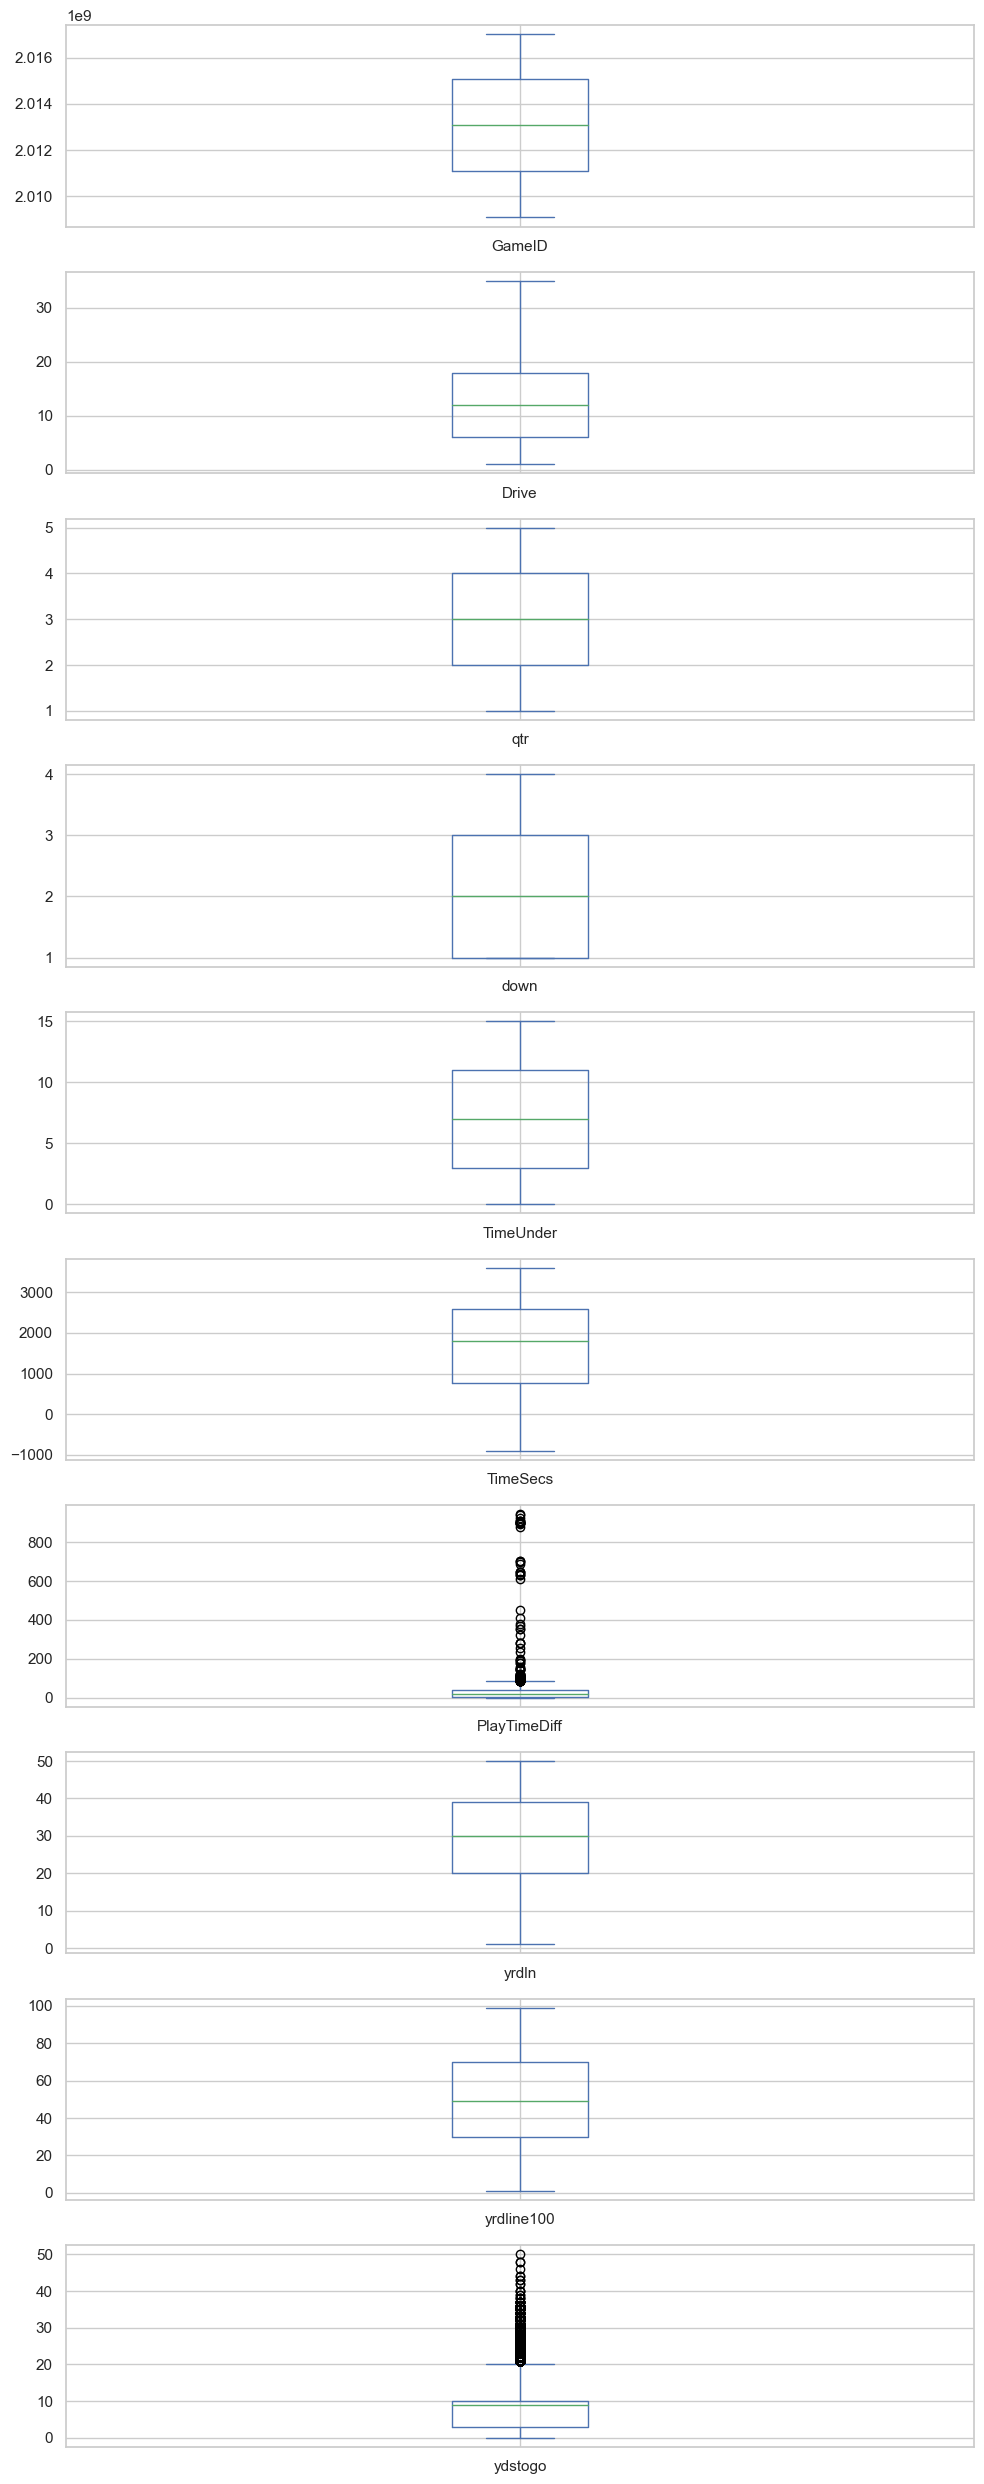

In [36]:
outlier_cols = [c for c in numeric_cols if df[c].notna().sum() > 0][:10]
if outlier_cols:
    df[outlier_cols].plot(kind="box", subplots=True, layout=(len(outlier_cols), 1),
                          figsize=(10, max(3, 2.5 * len(outlier_cols))), sharex=False)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for boxplots.")

In [37]:
# IQR-based outlier counts for selected numeric columns (counts only; no rows are removed)
outlier_summary = []
for col in numeric_cols:
    series = df[col].dropna()
    if len(series) < 4:
        continue
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    outlier_summary.append({"Column": col, "Outlier_Count_IQR": int(count), "Lower_Bound": lower, "Upper_Bound": upper})

display(pd.DataFrame(outlier_summary).sort_values("Outlier_Count_IQR", ascending=False).head(20))

,Column,Outlier_Count_IQR,Lower_Bound,Upper_Bound
25,Reception,90092,0.000000,0.000000
21,YardsAfterCatch,67038,0.000000,0.000000
20,AirYards,44962,-6.000000,10.000000
42,No_Score_Prob,37802,-0.250991,0.425792
60,WPA,36708,-0.058674,0.058885
14,Yards.Gained,31064,-10.500000,17.500000
62,yacWPA,28462,-0.063613,0.056360
52,EPA,27382,-2.343585,2.311292
15,sp,26158,0.000000,0.000000
30,Accepted.Penalty,26085,0.000000,0.000000


## 10. Feature engineering

Create date-based features only when a usable date column exists. For play-by-play datasets, the original clock and game-state columns should be interpreted according to their data definitions.

In [38]:
if "Date" in df.columns:
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Day"] = df["Date"].dt.day
    print("Added Year, Month, and Day features from Date.")
else:
    print("No Date column available; date features skipped.")

# Optional derived features when their source columns are available
if yards_col and down_col:
    df["Yards_Per_Down"] = (
        pd.to_numeric(df[yards_col], errors="coerce") /
        pd.to_numeric(df[down_col], errors="coerce").replace(0, np.nan)
    )
    print("Added Yards_Per_Down.")

display(df.head())

Added Year, Month, and Day features from Date.
Added Yards_Per_Down.


,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,FirstDown,posteam,DefensiveTeam,desc,PlayAttempted,Yards.Gained,sp,Touchdown,ExPointResult,TwoPointConv,DefTwoPoint,Safety,Onsidekick,PuntResult,PlayType,Passer,Passer_ID,PassAttempt,PassOutcome,PassLength,AirYards,YardsAfterCatch,QBHit,PassLocation,InterceptionThrown,Interceptor,Rusher,Rusher_ID,RushAttempt,RunLocation,RunGap,Receiver,Receiver_ID,Reception,ReturnResult,...,Fumble,RecFumbTeam,RecFumbPlayer,Sack,Challenge.Replay,ChalReplayResult,Accepted.Penalty,PenalizedTeam,PenaltyType,PenalizedPlayer,Penalty.Yards,PosTeamScore,DefTeamScore,ScoreDiff,AbsScoreDiff,HomeTeam,AwayTeam,Timeout_Indicator,Timeout_Team,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post,No_Score_Prob,Opp_Field_Goal_Prob,Opp_Safety_Prob,Opp_Touchdown_Prob,Field_Goal_Prob,Safety_Prob,Touchdown_Prob,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season,Year,Month,Day,Yards_Per_Down
0,2009-09-10,2009091000,1,1,NaN,15:00,15,3600.0,0.0,TEN,30.0,30.0,0,0,0.0,NaN,PIT,TEN,R.Bironas kicks 67 yards from TEN 30 to PIT 3....,1,39,0,0,NaN,NaN,NaN,0,0,NaN,Kickoff,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001506,0.179749,0.006639,0.281138,0.213700,0.003592,0.313676,0.0,0.0,0.323526,2.014474,NaN,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009,2009,9,10,NaN
1,2009-09-10,2009091000,1,1,1.0,14:53,15,3593.0,7.0,PIT,42.0,58.0,10,5,0.0,0.0,PIT,TEN,(14:53) B.Roethlisberger pass short left to H....,1,5,0,0,NaN,NaN,NaN,0,0,NaN,Pass,B.Roethlisberger,00-0022924,1,Complete,Short,-3,8,0,left,0,NaN,NaN,None,0,NaN,NaN,H.Ward,00-0017162,1,NaN,...,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.000969,0.108505,0.001061,0.169117,0.293700,0.003638,0.423011,0.0,0.0,2.338000,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009,2009,9,10,5.0
2,2009-09-10,2009091000,1,1,2.0,14:16,15,3556.0,37.0,PIT,47.0,53.0,5,2,0.0,0.0,PIT,TEN,(14:16) W.Parker right end to PIT 44 for -3 ya...,1,-3,0,0,NaN,NaN,NaN,0,0,NaN,Run,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,W.Parker,00-0022250,1,right,end,NaN,None,0,NaN,...,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001057,0.105106,0.000981,0.162747,0.304805,0.003826,0.421478,0.0,0.0,2.415907,-1.402760,NaN,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009,2009,9,10,-1.5
3,2009-09-10,2009091000,1,1,3.0,13:35,14,3515.0,41.0,PIT,44.0,56.0,8,2,0.0,0.0,PIT,TEN,(13:35) (Shotgun) B.Roethlisberger pass incomp...,1,0,0,0,NaN,NaN,NaN,0,0,NaN,Pass,B.Roethlisberger,00-0022924,1,Incomplete Pass,Deep,34,0,0,right,0,NaN,NaN,None,0,NaN,NaN,M.Wallace,00-0026901,0,NaN,...,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001434,0.149088,0.001944,0.234801,0.289336,0.004776,0.318621,0.0,0.0,1.013147,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009,2009,9,10,0.0
4,2009-09-10,2009091000,1,1,4.0,13:27,14,3507.0,8.0,PIT,44.0,56.0,8,2,0.0,1.0,PIT,TEN,(13:27) (Punt formation) D.Sepulveda punts 54 ...,1,0,0,0,NaN,NaN,NaN,0,0,Clean,Punt,NaN,None,0,NaN,NaN,0,0,0,NaN,0,NaN,NaN,None,0,NaN,NaN,NaN,None,0,NaN,...,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,PIT,TEN,0,None,3,3,3,3,3,0.001861,0.213480,0.003279,0.322262,0.244603,0.006404,0.208111,0.0,0.0,-0.699436,2.097796,NaN,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009,2009,9,10,0.0


## 11. Save the cleaned dataset

In [39]:
# Save a separate output file; the original CSV remains unchanged.
output_path = "NFL_Play_by_Play_Cleaned.csv"
df.to_csv(output_path, index=False)
print(f"Cleaned dataset saved to: {output_path}")
print("Final dataset shape:", df.shape)

Cleaned dataset saved to: NFL_Play_by_Play_Cleaned.csv
Final dataset shape: (362447, 106)


## 12. Final data-quality report

In [40]:
print("Final dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("Completely empty columns remaining:", int(df.isna().all().sum()))
print("Total missing values remaining:", int(df.isna().sum().sum()))
print("Columns with missing values:")
display(df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False).to_frame("Missing_Count"))

Final dataset shape: (362447, 106)
Duplicate rows remaining: 0
Completely empty columns remaining: 0
Total missing values remaining: 9244296
Columns with missing values:


,Missing_Count
DefTwoPoint,362433
BlockingPlayer,362341
TwoPointConv,361919
ChalReplayResult,359476
RecFumbPlayer,358513
...,...
Opp_Safety_Prob,148
Opp_Field_Goal_Prob,148
No_Score_Prob,148
Field_Goal_Prob,148


## 13. Findings and recommendations

After running the notebook, write conclusions based on the actual output rather than assuming results in advance.

Consider documenting:
- The number of rows and columns before and after cleaning.
- Which columns contain the most missing values and how those missing values were handled.
- The most frequent play types and teams in the dataset.
- Differences in yards gained by play type and down.
- Numeric relationships shown by the correlation heatmap.
- Potential outliers that require domain-specific review.
- Limitations, including missing data and differences in column names across dataset versions.

**Important:** This notebook removes exact duplicate rows and completely empty columns, and converts `Date` only when present. It does not automatically fill every missing value or remove outlier rows, because those choices can change the meaning of NFL play-by-play records.

## 14. Additional EDA Questions and Answers (Questions 15–25)

The following 11 questions extend the existing analysis to reach 25. Each code cell calculates its answer from the loaded `df` DataFrame. Run the cells after loading and cleaning the dataset. The exact numerical findings depend on the CSV file used.



In [41]:
# Helper functions for the additional questions
def find_column(candidates):
    return next((col for col in candidates if col in df.columns), None)

def numeric_series(column):
    return pd.to_numeric(df[column], errors="coerce")

def truthy_series(column):
    # Handles common numeric, Boolean, and text indicators.
    s = df[column]
    if pd.api.types.is_bool_dtype(s):
        return s.fillna(False)
    numeric = pd.to_numeric(s, errors="coerce")
    if numeric.notna().any():
        return numeric.fillna(0).ne(0)
    return s.astype(str).str.strip().str.lower().isin(["1", "true", "yes", "y"])


### Question 15. Which defensive teams faced the highest number of recorded plays?

**Answer:** The table shows the play count for each defensive team, sorted from highest to lowest. The first row identifies the team with the most recorded plays against it.


In [42]:
def_col = find_column(["defteam", "DefenseTeam", "defense_team", "DefensiveTeam"])
if def_col:
    answer = df[def_col].dropna().value_counts().rename_axis("Defensive_Team").to_frame("Plays_Faced")
    display(answer.head(10))
    if not answer.empty:
        print(f"Answer: {answer.index[0]} faced the most recorded plays ({int(answer.iloc[0, 0])}).")
else:
    print("Answer unavailable: no recognized defensive-team column was found.")


,Plays_Faced
Defensive_Team,
PHI,11030
DEN,10965
TEN,10947
CLE,10911
ARI,10894
BUF,10886
OAK,10879
MIA,10813
NE,10759


Answer: PHI faced the most recorded plays (11030).


### Question 16. Which quarter contains the most recorded plays?

**Answer:** The frequency table reports the number of plays in each quarter. The highest-count quarter is printed below the table.


In [43]:
quarter_col = find_column(["qtr", "quarter", "Quarter", "Qtr"])
if quarter_col:
    answer = df[quarter_col].dropna().value_counts().sort_index()
    display(answer.to_frame("Play_Count"))
    if not answer.empty:
        top_quarter = answer.idxmax()
        print(f"Answer: quarter {top_quarter} has the most recorded plays ({int(answer.max())}).")
else:
    print("Answer unavailable: no recognized quarter column was found.")


,Play_Count
1,79291
2,99701
3,80649
4,100198
5,2608


Answer: quarter 4 has the most recorded plays (100198).


### Question 17. How many recorded plays are rushing plays versus passing plays?

**Answer:** The code counts rows marked as rush attempts and pass attempts. These are indicator-column counts; a dataset version without those fields will be reported as unavailable.


In [44]:
rush_col = find_column(["rush_attempt", "RushAttempt", "rush"])
pass_col = find_column(["pass_attempt", "PassAttempt", "pass"])
if rush_col or pass_col:
    counts = {}
    if rush_col:
        counts["Rushing plays"] = int(truthy_series(rush_col).sum())
    if pass_col:
        counts["Passing plays"] = int(truthy_series(pass_col).sum())
    display(pd.Series(counts, name="Play_Count").to_frame())
    print("Answer: compare the counts above to see which type is more frequent.")
else:
    print("Answer unavailable: rush-attempt and pass-attempt indicator columns were not found.")


,Play_Count
Rushing plays,107448
Passing plays,149648


Answer: compare the counts above to see which type is more frequent.


### Question 18. Which offensive teams recorded the most rushing attempts?

**Answer:** The table ranks offensive teams by the sum of their rush-attempt indicator. The first row is the team with the most rushing attempts.


In [45]:
team_col = find_column(["posteam", "OffenseTeam", "offense_team"])
rush_col = find_column(["rush_attempt", "RushAttempt", "rush"])
if team_col and rush_col:
    temp = df.loc[truthy_series(rush_col) & df[team_col].notna(), team_col]
    answer = temp.value_counts().rename_axis("Offensive_Team").to_frame("Rushing_Attempts")
    display(answer.head(10))
    if not answer.empty:
        print(f"Answer: {answer.index[0]} recorded the most rushing attempts ({int(answer.iloc[0, 0])}).")
else:
    print("Answer unavailable: offensive-team or rush-attempt column was not found.")


,Rushing_Attempts
Offensive_Team,
NYJ,3887
CAR,3723
HOU,3691
KC,3604
CIN,3601
SEA,3589
BUF,3542
NE,3516
SF,3487


Answer: NYJ recorded the most rushing attempts (3887).


### Question 19. Which offensive teams recorded the most passing attempts?

**Answer:** The table ranks offensive teams by their number of pass attempts. The first row gives the highest count.


In [46]:
team_col = find_column(["posteam", "OffenseTeam", "offense_team"])
pass_col = find_column(["pass_attempt", "PassAttempt", "pass"])
if team_col and pass_col:
    temp = df.loc[truthy_series(pass_col) & df[team_col].notna(), team_col]
    answer = temp.value_counts().rename_axis("Offensive_Team").to_frame("Passing_Attempts")
    display(answer.head(10))
    if not answer.empty:
        print(f"Answer: {answer.index[0]} recorded the most passing attempts ({int(answer.iloc[0, 0])}).")
else:
    print("Answer unavailable: offensive-team or pass-attempt column was not found.")


,Passing_Attempts
Offensive_Team,
NO,5440
DET,5334
IND,5146
ATL,5079
NE,5070
ARI,4935
BAL,4900
DEN,4883
PHI,4882


Answer: NO recorded the most passing attempts (5440).


### Question 20. How often are penalties recorded, and what penalty types are most common?

**Answer:** The code first counts plays marked as penalties when an indicator is available. If a penalty-description column exists, it also displays the most frequent descriptions.


In [47]:
penalty_col = find_column(["penalty", "Penalty"])
penalty_type_col = find_column(["penalty_type", "PenaltyType", "penalty_type_text", "PenaltyTypeText"])
if penalty_col:
    penalty_mask = truthy_series(penalty_col)
    penalty_count = int(penalty_mask.sum())
    print(f"Answer: {penalty_count} rows are marked as penalties out of {len(df)} total rows.")
    print(f"Penalty rate: {penalty_count / len(df) * 100:.2f}%" if len(df) else "Penalty rate unavailable.")
    if penalty_type_col:
        display(df.loc[penalty_mask, penalty_type_col].fillna("Missing").value_counts().head(10).to_frame("Count"))
elif penalty_type_col:
    display(df[penalty_type_col].fillna("Missing").value_counts().head(10).to_frame("Count"))
else:
    print("Answer unavailable: no recognized penalty indicator or penalty-description column was found.")


,Count
Missing,347849
False Start,4774
Defensive Offside,1348
Defensive Holding,1254
Delay of Game,1074
Neutral Zone Infraction,855
Offensive Holding,631
Illegal Contact,526
Defensive Pass Interference,526
Encroachment,474


### Question 21. How many plays are recorded as interceptions?

**Answer:** The code counts rows marked as interceptions and calculates their percentage of the dataset.


In [48]:
interception_col = find_column(["interception", "Interception", "intercepted"])
if interception_col:
    interception_count = int(truthy_series(interception_col).sum())
    print(f"Answer: {interception_count} rows are marked as interceptions.")
    print(f"Percentage of all rows: {interception_count / len(df) * 100:.2f}%" if len(df) else "Percentage unavailable.")
else:
    print("Answer unavailable: no recognized interception indicator column was found.")


Answer unavailable: no recognized interception indicator column was found.


### Question 22. How many plays are recorded as fumbles?

**Answer:** The code counts rows marked as fumbles and reports the percentage of all rows. Check the column definition before interpreting this as fumbles lost, because those are not always the same measure.


In [49]:
fumble_col = find_column(["fumble", "Fumble", "fumbles"])
if fumble_col:
    fumble_count = int(truthy_series(fumble_col).sum())
    print(f"Answer: {fumble_count} rows are marked as fumbles.")
    print(f"Percentage of all rows: {fumble_count / len(df) * 100:.2f}%" if len(df) else "Percentage unavailable.")
else:
    print("Answer unavailable: no recognized fumble indicator column was found.")


Answer: 5173 rows are marked as fumbles.
Percentage of all rows: 1.43%


### Question 23. Which offensive teams recorded the most first downs?

**Answer:** When a first-down indicator and offensive-team column are available, the table ranks teams by the number of rows marked as first downs.


In [50]:
first_down_col = find_column(["first_down", "FirstDown", "firstdown"])
team_col = find_column(["posteam", "OffenseTeam", "offense_team"])
if first_down_col and team_col:
    mask = truthy_series(first_down_col) & df[team_col].notna()
    answer = df.loc[mask, team_col].value_counts().rename_axis("Offensive_Team").to_frame("First_Downs")
    display(answer.head(10))
    if not answer.empty:
        print(f"Answer: {answer.index[0]} has the highest first-down count ({int(answer.iloc[0, 0])}).")
else:
    print("Answer unavailable: first-down indicator or offensive-team column was not found.")


,First_Downs
Offensive_Team,
NO,3293
NE,3279
DEN,3254
HOU,3235
DET,3211
PHI,3207
IND,3174
ATL,3138
WAS,3116


Answer: NO has the highest first-down count (3293).


### Question 24. Is yards gained related to the yards needed for a first down?

**Answer:** The correlation value describes the strength and direction of a linear relationship between yards-to-go and yards gained. A value near zero means little linear relationship; correlation does not prove causation.


Answer: Pearson correlation between yards-to-go and yards gained = 0.047 (n=362447 plays).


,count,mean,std,min,25%,50%,75%,max
Yards_To_Go,362447.0,7.305236,4.863445,0.0,3.0,9.0,10.0,50.0
Yards_Gained,362447.0,5.034595,9.144627,-74.0,0.0,1.0,7.0,99.0


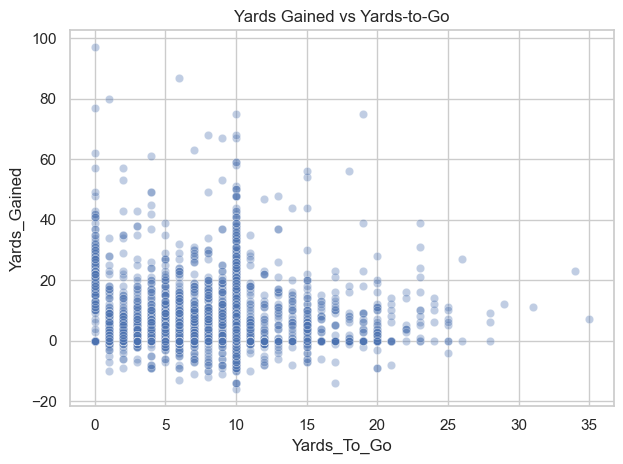

In [51]:
yards_col = find_column(["yards_gained", "Yards.Gained", "YardsGained"])
ydstogo_col = find_column(["ydstogo", "YardsToGo", "yards_to_go", "yards_to_gain"])
if yards_col and ydstogo_col:
    temp = pd.DataFrame({
        "Yards_To_Go": numeric_series(ydstogo_col),
        "Yards_Gained": numeric_series(yards_col)
    }).dropna()
    if len(temp) >= 2:
        corr_value = temp["Yards_To_Go"].corr(temp["Yards_Gained"])
        print(f"Answer: Pearson correlation between yards-to-go and yards gained = {corr_value:.3f} (n={len(temp)} plays).")
        display(temp.describe().T)
        sample = temp.sample(min(5000, len(temp)), random_state=42)
        sns.scatterplot(data=sample, x="Yards_To_Go", y="Yards_Gained", alpha=0.35)
        plt.title("Yards Gained vs Yards-to-Go")
        plt.tight_layout()
        plt.show()
    else:
        print("Answer unavailable: not enough complete numeric rows for correlation.")
else:
    print("Answer unavailable: yards-gained or yards-to-go column was not found.")


### Question 25. What down-and-distance situations occur most often?

**Answer:** The table lists the most common combinations of down and yards-to-go. This helps identify the game situations most frequently represented in the dataset.


In [52]:
down_col = find_column(["down", "Down"])
ydstogo_col = find_column(["ydstogo", "YardsToGo", "yards_to_go", "yards_to_gain"])
if down_col and ydstogo_col:
    situation = df[[down_col, ydstogo_col]].copy()
    situation[down_col] = pd.to_numeric(situation[down_col], errors="coerce")
    situation[ydstogo_col] = pd.to_numeric(situation[ydstogo_col], errors="coerce")
    situation = situation.dropna()
    situation = situation[situation[down_col].between(1, 4)]
    answer = (situation.groupby([down_col, ydstogo_col]).size()
              .sort_values(ascending=False).head(10)
              .rename("Play_Count").reset_index())
    display(answer)
    if not answer.empty:
        first = answer.iloc[0]
        print(f"Answer: down {int(first[down_col])} with {first[ydstogo_col]:g} yards to go is the most common listed situation ({int(first['Play_Count'])} plays).")
else:
    print("Answer unavailable: down or yards-to-go column was not found.")


,down,ydstogo,Play_Count
0,1.0,10,111499
1,2.0,10,21351
2,2.0,7,8125
3,2.0,8,7968
4,2.0,6,7525
5,2.0,5,6914
6,2.0,9,6772
7,3.0,1,6443
8,3.0,10,5750
9,2.0,4,5563


Answer: down 1 with 10 yards to go is the most common listed situation (111499 plays).


### How to write the final answers in your report

After running each code cell, use the printed result and table as the answer. Record the actual team names, counts, percentages, and correlation values shown by your CSV. If a cell says a required column was not found, note that the current dataset version does not support that question without additional data or a column-name adjustment.
